In [3]:
import math
import numpy as np
import scipy.stats as stats
import scipy.special as special
import pandas as pd
import matplotlib.pyplot as plt

С помощью пакета scipy.stats вычислите следующие вероятности:

Для X принадлежащей N(x;0,1) и для X принадлежащей T(x;5)

a, для которого P(X (принадлежит) [-a; a]) = 0.8

b, для которого P(X > b) = 0.4

c, для которого P(X < -c) + P(X > c) = 0.3

In [9]:
norm_dist = stats.norm(loc=0, scale=1)
t_dist = stats.t(df=5)

a_norm = norm_dist.ppf(0.9)
a_t = t_dist.ppf(0.9)


b_norm = norm_dist.ppf(0.6)
b_t = t_dist.ppf(0.6)

c_norm = norm_dist.ppf(0.85)
c_t = t_dist.ppf(0.85)

print(f'a_norm: {a_norm}\nb_norm: {b_norm}\nc_norm: {c_norm}\n')
print(f'a_t: {a_t}\nb_t: {b_t}\nc_t: {c_t}')

a_norm: 1.2815515655446004
b_norm: 0.2533471031357997
c_norm: 1.0364333894937898

a_t: 1.4758840488244815
b_t: 0.2671808657041451
c_t: 1.1557673428942927


Для X (принадлежит) N (x;0,1) и для X (принадлежит) T(x;5)

gamma1, для которой P(X (принадлежит) [-0.1, 0.1]) = gamma1 

gamma2, для которой P(X > 0.7) = gamma2

gamma3, для которой  P(X < -0.4) + P(X > 0.4) = gamma3

In [8]:
gamma1_norm = norm_dist.cdf(0.1) - norm_dist.cdf(-0.1)
gamma1_t = t_dist.cdf(0.1) - t_dist.cdf(-0.1)


gamma2_norm = 1 - norm_dist.cdf(0.7)
gamma2_t = 1 - t_dist.cdf(0.7)

gamma3_norm = norm_dist.cdf(-0.4) + (1 - norm_dist.cdf(0.4))
gamma3_t = t_dist.cdf(-0.4) + (1 - t_dist.cdf(0.4))

print(f'gamma1_norm: {gamma1_norm}\ngamma2_norm: {gamma2_norm}\ngamma3_norm: {gamma3_norm}\n')
print(f'gamma1_t: {gamma1_t}\ngamma2_t: {gamma2_t}\ngamma3_t: {gamma3_t}')

gamma1_norm: 0.07965567455405798
gamma2_norm: 0.24196365222307303
gamma3_norm: 0.6891565167793516

gamma1_t: 0.07576985884533954
gamma2_t: 0.2575744741574082
gamma3_t: 0.7056731148331146


Для найти X (принадлежит) chi^2(x;10):

a, для которого P(X > a) = 0.4

b, для которого P(X < b) = 0.4

gamma, для которой P(X > 12) = gamma 

In [16]:
chi_dist = stats.chi(df=10)
a_chi = chi_dist.ppf(0.6)
b_chi = chi_dist.ppf(0.4)
gamma_chi = 1 - chi_dist.cdf(12)

print(f'a_chi: {a_chi}\nb_chi: {b_chi}\ngamma_chi: {gamma_chi}')

a_chi: 3.2362379750870387
b_chi: 2.880186063597469
gamma_chi: 0.0


2. В scipy.stats сделайте реализацию выборки объемом N элементов из генеральной совокупности, распределенной по нормальному закону распределения

Вариант 6 std=0.4 m=6 N=60

In [17]:
norm_dist_2 = stats.norm(loc=6, scale=0.4)
sample = norm_dist_2.rvs(size=60)

sample

array([5.62603797, 6.18472664, 5.99895972, 5.62143897, 5.63395168,
       5.8841321 , 6.41493052, 6.37746214, 6.27888648, 5.88498358,
       6.49024006, 6.11260947, 6.51710688, 5.94411692, 6.24334632,
       6.05322927, 6.3617548 , 5.84338196, 5.27605953, 5.83996707,
       6.25467887, 6.14936245, 5.58952352, 5.82717798, 5.84914276,
       6.61373004, 5.96507593, 6.63750811, 6.30362407, 6.28604232,
       5.60733036, 5.56638945, 5.34258085, 6.50936816, 6.11584427,
       5.91139627, 6.91988577, 5.45416452, 6.33949461, 6.48428483,
       5.66521863, 5.80468044, 6.76064306, 6.95561102, 6.01884588,
       5.76579926, 5.89897144, 6.05801495, 5.59282573, 6.14482027,
       6.08340208, 6.61003124, 5.81789394, 6.49590194, 5.83830797,
       6.26702544, 5.19731429, 5.63103302, 6.21860294, 6.36026916])

3.1 Для математического ожидания генеральной совокупности в предположении, что
среднеквадратичное отклонение известно

In [18]:
a =(1.96 * 0.4) / math.sqrt(60)
sample_mean = np.mean(sample)

print(f'({(sample_mean - a):.2f};{(sample_mean + a):.2f})')

(5.96;6.16)


3.2 Для математического ожидания генеральной совокупности в предположении, что
среднеквадратичное отклонение НЕизвестно.

In [19]:
B = special.gamma(29) / (np.sqrt(np.pi * 59) * special.gamma(29.5))
S = B * (1 + (2.001 ** 2 / 59)) ** (-29.5)
level = 2.001 * S / np.sqrt(60)

print(f'({(sample_mean - level):.4f};{(sample_mean + level):.4f})')

(6.0578;6.0588)


3.3 Для дисперсии генеральной совокупности в предположением, что математическое ожидание НЕизвестно.

In [20]:
sum = 0
for i in range(len(sample)):
    sum += (sample[i] - sample_mean) ** 2
print(f'general var: {(sum / (len(sample) - 1)):.4f}')
print(f'local var: {(sum / len(sample)):.4f}')

general var: 0.1590
local var: 0.1564


4. Определите, сколько необходимо провести испытаний N1, чтобы доверительный интервал для математического ожидания (а) уменьшился в 2 раза (новая ширина ε1=ε/2) с той же доверительной вероятностью γ.

In [21]:
print("В 4 раза (см. тетрадь)")

В 4 раза (см. тетрадь)


5.1 Из всей таблицы взять данные для 10 стран в определенный месяц. (Выбрать страны и месяц можно произвольно)

In [22]:
df = pd.read_csv("daily_weather_data.csv")
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')
august_data = df[df['date'].dt.month == 8]
countries = df['country'].drop_duplicates().head(10)

df = august_data[august_data['country'].isin(countries)]

df

,date,country,city,Latitude,Longitude,tavg,tmin,tmax,wdir,wspd,pres
11,2018-08-01,Abkhazia,Sukhumi,43.001525,41.023415,26.4,24.7,28.3,341.0,9.1,1008.5
12,2018-08-02,Abkhazia,Sukhumi,43.001525,41.023415,25.4,23.4,27.0,102.0,9.5,1008.7
13,2018-08-03,Abkhazia,Sukhumi,43.001525,41.023415,24.5,22.9,25.8,106.0,10.4,1007.9
14,2018-08-04,Abkhazia,Sukhumi,43.001525,41.023415,23.8,22.0,25.3,105.0,12.0,1008.8
15,2018-08-05,Abkhazia,Sukhumi,43.001525,41.023415,24.1,21.3,26.5,110.0,10.2,1012.4
...,...,...,...,...,...,...,...,...,...,...,...
17172,2022-08-27,Aruba,Oranjestad,12.509204,-70.008631,28.2,19.7,31.7,94.0,20.0,1010.5
17173,2022-08-28,Aruba,Oranjestad,12.509204,-70.008631,29.2,27.6,31.7,103.0,28.4,1011.3
17174,2022-08-29,Aruba,Oranjestad,12.509204,-70.008631,29.5,27.7,33.7,95.0,27.8,1012.6
17175,2022-08-30,Aruba,Oranjestad,12.509204,-70.008631,29.0,27.5,31.7,96.0,24.5,1012.5


5.2 Для каждой из стран построить доверительные интервалы для математического ожидания
и дисперсии случайной величины «tavg».

In [23]:
alpha = 0.05
results = []

for country, group in df.groupby('country'):
    current_country = group['tavg'].dropna()
    n = len(current_country)
    
    mean = current_country.mean()
    
    t = stats.t.ppf(1 - alpha / 2, df=n-1)
    mean_level = t * current_country.std() / np.sqrt(n)
    mean_lower = mean - mean_level
    mean_upper = mean + mean_level
    
    var = current_country.var()
    
    chi_lower = stats.chi2.ppf(alpha / 2, df=n-1)
    chi_upper = stats.chi2.ppf(1 - alpha / 2, df=n-1)
    var_lower = (n-1) * var / chi_upper
    var_upper = (n-1) * var / chi_lower
    results.append({
        'country'   : country,
        'mean' : round(mean, 3),
        'err' : round(mean_level, 3),
        'mean_lower': round(mean_lower, 3),
        'mean_upper': round(mean_upper, 3),
        'var' : round(var, 3),
        'var_lower' : round(var_lower,  3),
        'var_upper' : round(var_upper,  3)
    })
    
    
result_df = pd.DataFrame(results)

result_df

,country,mean,err,mean_lower,mean_upper,var,var_lower,var_upper
0,Abkhazia,24.670,0.266,24.403,24.936,2.817,2.280,3.569
1,Aland Islands,16.525,0.408,16.116,16.933,6.613,5.353,8.380
2,Albania,26.448,0.325,26.123,26.773,4.195,3.395,5.315
3,Algeria,26.436,0.248,26.188,26.684,2.441,1.976,3.093
4,American Samoa,26.438,0.144,26.295,26.582,0.818,0.663,1.037
5,Angola,22.307,0.139,22.168,22.446,0.770,0.623,0.976
6,Anguilla,28.392,0.098,28.293,28.490,0.385,0.312,0.488
7,Antigua and Barbuda,28.155,0.085,28.070,28.241,0.289,0.234,0.367
8,Argentina,12.167,0.423,11.744,12.590,7.103,5.750,9.001
9,Aruba,28.900,0.085,28.815,28.985,0.286,0.232,0.363


5.3 Построить доверительные интервалы на графиках errorbar. 

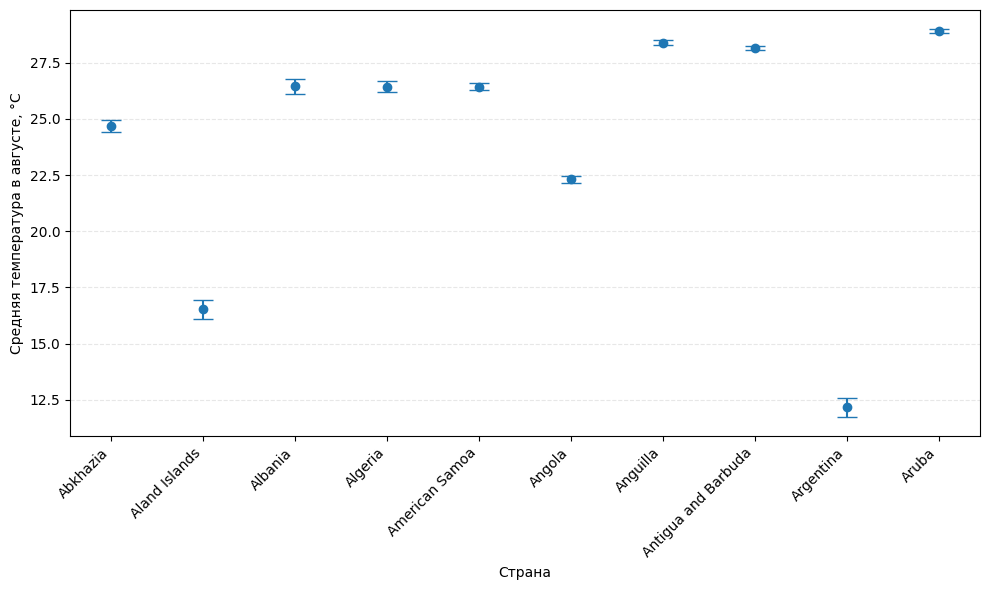

In [33]:
plt.figure(figsize=(10, 6))
plt.errorbar(
    x=result_df['country'],
    y=result_df['mean'],
    yerr=result_df['err'],
    fmt='o',               
    capsize=7,     
)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Страна')
plt.ylabel('Средняя температура в августе, °C')
plt.grid(True, axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()